# Jupyter notebooks

`jupyter`, one of [little's own plugins](using-plugins.md#littles-own-plugins),
makes each Jupyter notebook in `docs/`, `.ipynb`, a
[page](using-plugins.md#pages-in-other-formats), as it was saved, outputs
and all, without Jupyter or Python. Name it in your site's
[`plugins`](using-plugins.md#naming-a-plugin):

```yaml
# little.yml
plugins:
  jupyter: https://github.com/withlittle/little/releases/download/jupyter-v0.1.0/little_jupyter.wasm
```

It has no settings. This page is a notebook, `docs/plugins/jupyter.ipynb`:
its Markdown cells are Markdown, and its code cells are code blocks,
highlighted in the notebook's language, each followed by its outputs.

## Code, and what it printed

What the code printed, and a result that's only text, are code blocks in
`output`, which aren't highlighted. Terminal colours are left out, and a
progress bar shows as it ended.

In [1]:
words = ["little", "builds", "notebooks"]
for word in words:
    print(word.upper())

LITTLE
BUILDS
NOTEBOOKS


In [2]:
sum(len(word) for word in words)

21

## Tables

A table pandas shows is its HTML, so it needs
[HTML](../writing/markdown.md#html) in Markdown, which is on unless you turn
it off. Without it, the table shows its text.

In [3]:
import pandas as pd

files = pd.DataFrame({
    "kind": ["Markdown", "Notebook", "Image"],
    "files": [5, 1, 1],
})
files

,kind,files
0,Markdown,5
1,Notebook,1
2,Image,1


## Charts and images

A chart is an image in the page itself, with a `data:` URL, so it needs no
file beside the notebook. A chart in SVG, like this one, needs HTML too, and
without it shows its PNG, if it has one, or its text.

An image attached to a Markdown cell, like
`![chart.png](attachment:chart.png)`, is in the page too, but one shown with
an HTML `<img>` isn't.

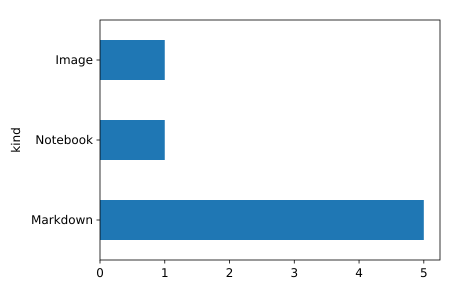

In [4]:
files.plot.barh(x="kind", y="files", legend=False);

## Errors

When code fails, its traceback follows it.

In [5]:
words[3]

IndexError: list index out of range

## Writing your own

Save a notebook in `docs/` with its outputs, and it's a page, with its
title, table of contents, links, math, like $e^{i\pi} + 1 = 0$, diagrams,
and footnotes, as in a Markdown file, except that:

- Its frontmatter goes in a raw or Markdown cell at its top, as Quarto and
  MyST put it, and as this one's is. Other raw cells are left out.
- Each Markdown cell is read on its own, as Jupyter shows it, so a
  footnote's text goes in the cell that refers to it, and notes in
  different cells need different names.
- An output that needs Jupyter's JavaScript to show it, like a widget,
  shows its text, or nothing.
- Code blocks in its Markdown cells, and in Markdown a cell showed, go to
  [plugins](using-plugins.md#code-blocks), but its code cells don't.